# Part 1 · 五组收益与因子暴露

**分析对象**是主 Fama–MacBeth 岭回归的固定 50 只股票。第一部分检查每月的预测排序能否区分下月实际收益，并把固定池整体下跌与极端预测组之间的相对表现放在一起。第二部分逐月还原筛选结果、股票因子暴露和预测贡献，便于追踪两组的差异从哪些特征来。

结果从仓库的主预测表、实际收益表和原始行情重建。建议用 Part 1 notebook 的 Python 3.11 内核运行。全程在本 notebook 内计算，末尾可选导出供后续分析。

**本次结果。** 最高组比最低组平均每月多 2.68 个百分点，116 个月中有 60.3% 的月份胜出。中间三组的顺序不完全单调。2015 年股灾窗口里，两端组差对回退预测较敏感。下方把分组、等权基准和因子贡献拆开看。

方法来源见 [Part 1 构建逻辑](../logic_readme.md)、[主模型 notebook](Part1_Return_Model.ipynb) 和 [因子筛选与拟合代码](../../src/sta4020_project/part1/forecasts.py)。

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq
from scipy.stats import spearmanr
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
root = next(
    (path for path in (cwd, *cwd.parents) if (path / "src" / "sta4020_project").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError("从仓库根目录或其子目录启动 notebook。")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

from sta4020_project.part1.features import TRAIN_MONTHS, ReturnFeatures
from sta4020_project.part1.forecasts import fama_macbeth_ridge, rank_features, screen_factors, training_statistics
from sta4020_project.shared.contracts import read_wide

data_dir = root / "data"
part1_dir = root / "artifacts" / "part1"
expected = read_wide(part1_dir / "P1_Expected_Returns.csv")
realised = read_wide(part1_dir / "Actual_Returns.csv")
pool = pd.Index(pd.read_csv(part1_dir / "P1_Candidate_Universe.csv")["Asset"], name="asset")
forecast_months = expected.index.to_period("M")
outcome_months = forecast_months + 1

assert len(pool) == 50 and pool.is_unique
assert expected.columns.is_unique and realised.columns.is_unique
assert set(expected.columns) == set(realised.columns) == set(pool)
assert expected.index.is_month_end.all() and realised.index.is_month_end.all()
assert forecast_months.equals(pd.period_range(forecast_months[0], forecast_months[-1], freq="M", name="Date"))
assert realised.index.to_period("M").equals(outcome_months)
assert np.isfinite(expected.to_numpy()).all() and np.isfinite(realised.to_numpy()).all()
assert realised.ge(-1).all().all()
realised = realised.loc[:, expected.columns]

GROUPS = ["Q1", "Q2", "Q3", "Q4", "Q5"]
GROUP_LABELS = {
    "Q1": "Q1 Highest", "Q2": "Q2", "Q3": "Q3", "Q4": "Q4", "Q5": "Q5 Lowest",
}
COLORS = dict(zip(GROUPS, ["#00796b", "#62a48d", "#8e8e8e", "#cf8178", "#ae3d48"]))
STRESS_WINDOWS = {
    "2015 年股灾（6–8 月）": ("2015-06", "2015-08"),
    "2022 年下半年（7–12 月）": ("2022-07", "2022-12"),
}
FACTOR_LABELS = {
    "log_size": "Market cap",
    "log_amount_21d": "21-day traded value",
    "return_5d": "5-day return",
    "volatility_63d": "63-day volatility",
    "momentum_8w": "8-week momentum",
    "volatility_12w": "12-week volatility",
    "momentum_12_1m": "12–1 month momentum",
    "lagged_month_return": "Prior-month return",
    "return_month_to_signal": "Month-to-signal return",
    "pc1_market_beta": "First principal component",
    "pca_residual_volatility": "Principal component residual volatility",
}

print(f"{len(forecast_months)} 个实现月 × {len(pool)} 只股票 · {outcome_months[0]} 至 {outcome_months[-1]}")

116 个实现月 × 50 只股票 · 2015-01 至 2024-08


### 复用主模型的筛选与拟合

使用仓库的特征构建、排名变换、Benjamini–Yekutieli 筛选和 Fama–MacBeth 岭回归。对每个预测月只使用当时已实现的 72 个月训练标签，保存所有候选的筛选记录以及入选因子在固定池内的暴露。下游分析前逐个股票月比较重建预测与交付 CSV。这个检查保证暴露和分层使用的是同一版预测。

In [2]:
features = ReturnFeatures(data_dir, forecast_months)
assets = pd.Index(expected.columns, name="asset")
forecast_dates = dict(zip(forecast_months, expected.index))
target_dates = dict(zip(forecast_months, realised.index))

training_stats = {}
rebuilt_rows = []
stock_rows = []
screening_rows = []
exposure_rows = []
history_months = pd.period_range(forecast_months[0] - TRAIN_MONTHS - 1, forecast_months[-1], freq="M")

with threadpool_limits(limits=1):
    for month in history_months:
        raw = features.at(month)
        scores = rank_features(raw)

        if month in forecast_dates:
            origin = forecast_dates[month]
            target = target_dates[month]
            signal_date = features.signal_close.loc[month]
            train_months = pd.period_range(month - TRAIN_MONTHS - 1, month - 2, freq="M")
            latest_label_close = features.last_close.loc[train_months[-1] + 1]
            assert latest_label_close < signal_date
            training = [training_stats[previous] for previous in train_months]
            ic_history = pd.DataFrame([record["ic"] for record in training], index=train_months)
            selected, audit = screen_factors(ic_history)
            coefficients = fama_macbeth_ridge(training, selected, scores.columns)
            slopes = pd.Series(coefficients[1:], index=selected, dtype=float)
            fresh = pd.Series(assets.isin(scores.index), index=assets, name="fresh_signal")
            common_level = float(np.mean([record["raw_return_mean"] for record in training]))

            rank_exposure = scores.reindex(assets)[selected]
            model_exposure = rank_exposure.fillna(0.0).where(fresh, axis=0)
            contribution = model_exposure.mul(slopes, axis=1)
            model_base = pd.Series(np.where(fresh, coefficients[0], common_level), index=assets)
            rebuilt_rows.append(model_base + contribution.sum(axis=1))

            date_fields = {"formation_date": origin, "signal_date": signal_date, "realization_date": target}
            stock_rows.append(pd.DataFrame({
                **date_fields,
                "fresh_signal": fresh,
                "prediction_base": model_base,
                "predicted_return": expected.loc[origin].reindex(assets),
                "realized_return": realised.loc[target].reindex(assets),
            }).rename_axis("asset").reset_index())

            screening_rows.append(audit.rename_axis("factor").reset_index().assign(
                **date_fields,
                latest_label_close=latest_label_close,
                selected=lambda frame: frame["factor"].isin(selected),
                coefficient=lambda frame: frame["factor"].map(slopes),
            ))
            raw_selected = raw.reindex(assets)[selected]
            for factor in selected:
                exposure_rows.append(pd.DataFrame({
                    **date_fields,
                    "factor": factor,
                    "raw_feature": raw_selected[factor],
                    "rank_exposure": rank_exposure[factor],
                    "model_exposure": model_exposure[factor],
                    "feature_imputed": fresh & rank_exposure[factor].isna(),
                    "coefficient": slopes[factor],
                    "forecast_contribution": contribution[factor],
                }).rename_axis("asset").reset_index())

        if month <= forecast_months[-1] - 2:
            next_return = features.returns.loc[month + 1].reindex(scores.index)
            training_stats[month] = training_statistics(scores, next_return)

rebuilt = pd.DataFrame(rebuilt_rows, index=expected.index)
np.testing.assert_allclose(rebuilt.to_numpy(), expected.to_numpy(), atol=1e-9, rtol=0)
stock_panel = pd.concat(stock_rows, ignore_index=True)
factor_screen = pd.concat(screening_rows, ignore_index=True)
selected_factor_exposures = pd.concat(exposure_rows, ignore_index=True)
assert not selected_factor_exposures.duplicated(["formation_date", "asset", "factor"]).any()
assert len(factor_screen) == len(expected) * len(FACTOR_LABELS)
max_prediction_error = (rebuilt - expected).abs().to_numpy().max()
print(f"重建了 {stock_panel.shape[0]:,} 条股票月预测，最大绝对差 {max_prediction_error:.2e}。")

重建了 5,800 条股票月预测，最大绝对差 1.01e-16。


## 1. 按预测收益分五组

每个信号月把 50 只股票按交付预测从高到低排列。同分按股票代码升序，Q1 到 Q5 各 10 只，Q1 最高。组内对下一月实际收益取等权平均。分组收益是**未计费用和成交约束的排序诊断**。另外复刻主 notebook 的固定池等权净值（每只有效信号股票目标权重 2%、缺报价或不可交易时冻结、买卖各 20 个基点、现金赚取无风险收益），用来核对截图对应的组合口径。中证 500 使用价格指数。

完整 50 只的分组保留了回退到共同均值的预测。另算只用当月有效信号股票的五组、Rank IC 和最高减最低组差，检查结果对回退值的敏感性。有效信号口径的组大小会随月份变化。

In [3]:
def rank_and_group(panel):
    ranked = panel.sort_values(
        ["formation_date", "predicted_return", "asset"], ascending=[True, False, True],
    ).copy()
    by_month = ranked.groupby("formation_date", sort=False)
    ranked["score_rank"] = by_month.cumcount() + 1
    month_size = by_month["asset"].transform("size")
    assert month_size.ge(len(GROUPS)).all()
    group_number = ((ranked["score_rank"] - 1) * len(GROUPS)) // month_size
    ranked["quintile"] = group_number.map(dict(enumerate(GROUPS)))
    return ranked

def group_returns(panel):
    return panel.groupby(["realization_date", "quintile"])["realized_return"].mean().unstack()[GROUPS]

stock_panel = rank_and_group(stock_panel)
fresh_panel = rank_and_group(stock_panel.loc[stock_panel["fresh_signal"]])
quintile_monthly = group_returns(stock_panel)
fresh_quintile_monthly = group_returns(fresh_panel)
assert stock_panel.groupby(["formation_date", "quintile"]).size().eq(10).all()

pool_gross = realised.mean(axis=1).rename("Fixed pool gross equal weight")
np.testing.assert_allclose(quintile_monthly.mean(axis=1), pool_gross, atol=1e-14, rtol=0)
index_close = pd.read_pickle(data_dir / "zz500.pk")["close"].sort_index()
index_months = pd.period_range(forecast_months[0], outcome_months[-1], freq="M")
index_prices = index_close.reindex(features.last_close.loc[index_months].to_numpy())
assert np.isfinite(index_prices).all() and index_prices.gt(0).all()
csi500 = (
    index_prices.pct_change(fill_method=None).iloc[1:]
    .set_axis(realised.index)
    .rename("CSI 500 price index")
)

def fixed_pool_equal_weight_net():
    risk_free = pd.read_csv(data_dir / "risk_free.csv", index_col="date", parse_dates=True)["RF"]
    daily_rf = risk_free.reindex(features.prices.index)
    monthly_rf = (1 + daily_rf).groupby(daily_rf.index.to_period("M")).prod(min_count=1) - 1
    assert monthly_rf.reindex(outcome_months).notna().all()
    signal_flags = stock_panel.pivot(index="formation_date", columns="asset", values="fresh_signal")
    pretrade = np.zeros(len(assets))
    net_returns = []
    fee_rate = 0.002
    for month, origin in forecast_dates.items():
        trade_date = features.last_close.loc[month]
        blocked = assets.isin(features.untradable.get(trade_date, ()))
        frozen = features.prices.loc[trade_date, assets].isna().to_numpy() | blocked
        blacklisted = assets.isin(features.blacklist.get(trade_date, ()))
        desired = (signal_flags.loc[origin, assets].to_numpy() & ~blacklisted & ~frozen) / len(assets)
        frozen_value = pretrade[frozen].sum()
        target_total = desired.sum()

        def positions_after_fee(fee):
            available = max(0.0, 1.0 - frozen_value - fee)
            scale = min(1.0, available / target_total) if target_total else 0.0
            return np.where(frozen, pretrade, desired * scale)

        fee = brentq(
            lambda fee: fee - fee_rate * np.abs(positions_after_fee(fee) - pretrade).sum(),
            0.0, 2 * fee_rate + 1e-10,
        )
        weights = positions_after_fee(fee) / (1.0 - fee)
        cash_weight = max(0.0, 1.0 - weights.sum())
        actual = realised.loc[target_dates[month], assets].to_numpy()
        gross = weights @ actual + cash_weight * monthly_rf.loc[month + 1]
        net_returns.append((1.0 - fee) * (1.0 + gross) - 1.0)
        pretrade = weights * (1.0 + actual) / (1.0 + gross)
    return pd.Series(net_returns, index=realised.index, name="Fixed pool net equal weight")

pool_net = fixed_pool_equal_weight_net()
monthly_benchmarks = pd.concat([pool_gross, pool_net, csi500], axis=1)
spread = (quintile_monthly["Q1"] - quintile_monthly["Q5"]).rename("Q1 minus Q5")
fresh_spread = (fresh_quintile_monthly["Q1"] - fresh_quintile_monthly["Q5"]).rename("Fresh-signal Q1 minus Q5")

def monthly_rank_ic(panel):
    return pd.Series({
        date: spearmanr(group["predicted_return"], group["realized_return"]).statistic
        for date, group in panel.groupby("realization_date")
    })

def compound(returns):
    return (1.0 + returns).prod() - 1.0

def drawdown(returns):
    wealth = (1.0 + returns).cumprod()
    return (wealth / wealth.cummax().clip(lower=1.0) - 1.0).min()

def return_table(returns):
    return pd.DataFrame({
        "Mean monthly": returns.mean(),
        "Annualized compound": (1 + compound(returns)) ** (12 / len(returns)) - 1,
        "Annualized volatility": returns.std() * np.sqrt(12),
        "Maximum drawdown": drawdown(returns),
    })

all_returns = quintile_monthly.join(monthly_benchmarks)
quintile_summary = return_table(all_returns)
ordering_summary = pd.DataFrame({
    "Mean monthly rank IC": [monthly_rank_ic(stock_panel).mean(), monthly_rank_ic(fresh_panel).mean()],
    "Mean monthly Q1 minus Q5": [spread.mean(), fresh_spread.mean()],
    "Months Q1 beat Q5": [spread.gt(0).mean(), fresh_spread.gt(0).mean()],
}, index=["All 50 stocks", "Fresh signals only"])

display(quintile_summary.style.format("{:.2%}"))
display(ordering_summary.style.format({
    "Mean monthly rank IC": "{:.4f}", "Mean monthly Q1 minus Q5": "{:+.2%}", "Months Q1 beat Q5": "{:.1%}",
}))

stress_rows = {}
for window, (start, end) in STRESS_WINDOWS.items():
    window_returns = all_returns.loc[start:end]
    stress_rows[window] = pd.concat({
        "Period return": compound(window_returns),
        "Maximum drawdown": drawdown(window_returns),
    }, axis=1)
stress_returns = pd.concat(stress_rows, axis=1)
window_spread = pd.DataFrame([
    {
        "Window": window,
        "Months": len(spread.loc[start:end]),
        "Mean monthly Q1 minus Q5": spread.loc[start:end].mean(),
        "Mean monthly Q1 minus Q5, fresh signals": fresh_spread.loc[start:end].mean(),
        "Mean monthly pool gross minus CSI 500": (pool_gross - csi500).loc[start:end].mean(),
        "Share of fallback forecasts": 1.0 - stock_panel.set_index("realization_date").sort_index()
            .loc[start:end, "fresh_signal"].mean(),
    }
    for window, (start, end) in STRESS_WINDOWS.items()
]).set_index("Window")
display(stress_returns.style.format("{:.2%}"))
display(window_spread.style.format({
    column: "{:.2%}" for column in window_spread if column != "Months"
}))

,Mean monthly,Annualized compound,Annualized volatility,Maximum drawdown
Q1,2.33%,22.84%,39.54%,-55.34%
Q2,1.71%,15.21%,35.93%,-48.27%
Q3,0.86%,3.94%,36.37%,-59.57%
Q4,1.42%,10.88%,37.43%,-51.65%
Q5,-0.35%,-10.35%,36.70%,-87.75%
Fixed pool gross equal weight,1.19%,8.92%,34.51%,-49.68%
Fixed pool net equal weight,1.07%,7.54%,33.76%,-49.97%
CSI 500 price index,0.13%,-1.41%,24.46%,-58.18%


,Mean monthly rank IC,Mean monthly Q1 minus Q5,Months Q1 beat Q5
All 50 stocks,0.1219,+2.68%,60.3%
Fresh signals only,0.1288,+2.48%,62.1%


,Months,Mean monthly Q1 minus Q5,"Mean monthly Q1 minus Q5, fresh signals",Mean monthly pool gross minus CSI 500,Share of fallback forecasts
Window,,,,,
2015 年股灾（6–8 月）,3,-2.42%,5.77%,-2.96%,15.33%
2022 年下半年（7–12 月）,6,3.08%,2.97%,1.81%,8.67%


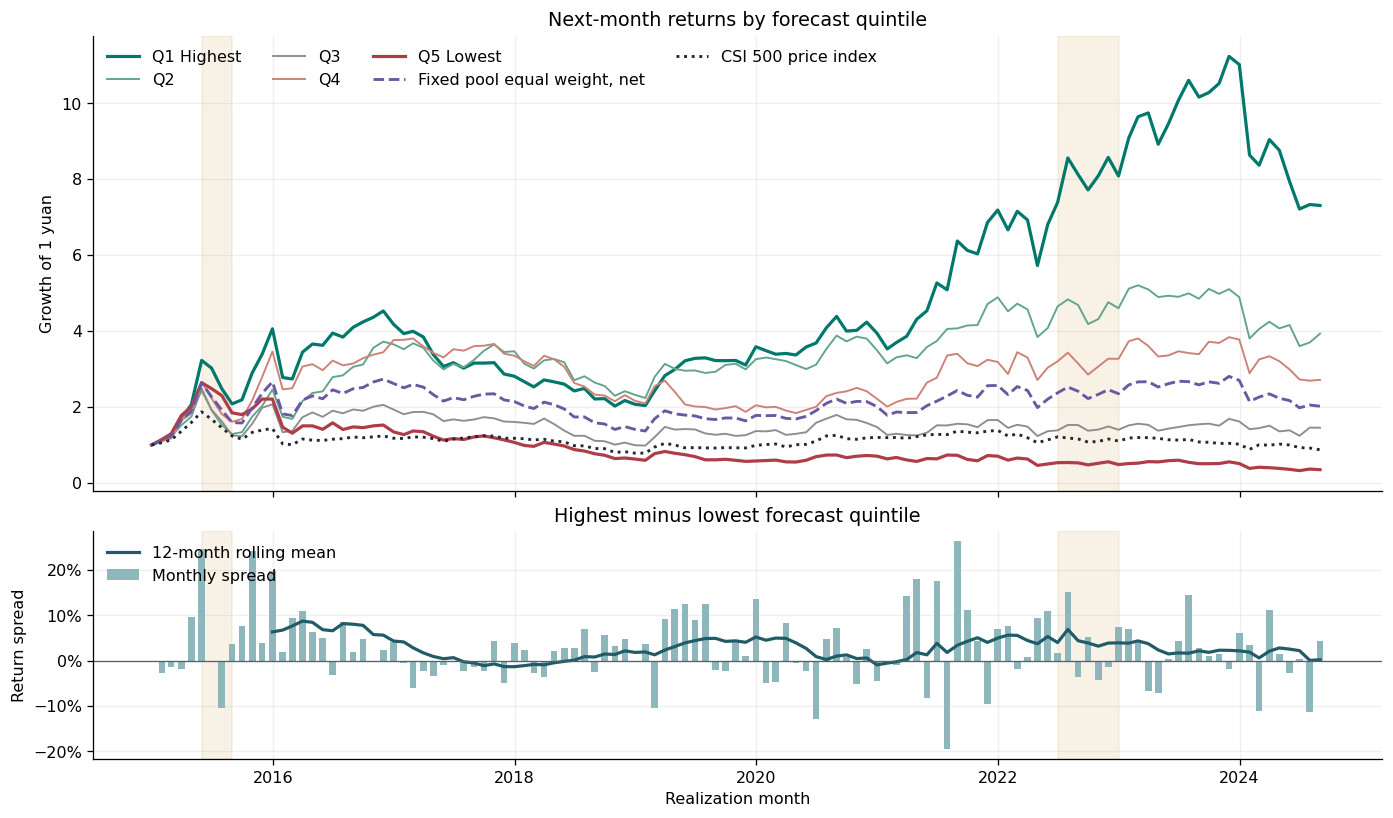

quintile,Q1,Q2,Q3,Q4,Q5
realization_date,,,,,
2024-01-31 00:00:00,-21.64%,-22.24%,-12.58%,-23.45%,-25.10%
2024-02-29 00:00:00,-3.10%,6.58%,2.00%,12.55%,8.09%
2024-03-31 00:00:00,8.09%,4.70%,4.45%,2.56%,-3.09%
2024-04-30 00:00:00,-3.13%,-4.09%,-9.91%,-3.91%,-4.48%
2024-05-31 00:00:00,-9.40%,2.12%,2.03%,-6.76%,-6.58%
2024-06-30 00:00:00,-9.12%,-13.34%,-10.43%,-8.83%,-9.38%
2024-07-31 00:00:00,1.63%,2.68%,17.36%,-1.23%,12.84%
2024-08-31 00:00:00,-0.34%,6.28%,-0.23%,0.87%,-4.59%


In [4]:
plt.rcParams.update({
    "figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.20, "font.size": 10,
})
initial = expected.index[0]
wealth = pd.concat([
    pd.DataFrame(1.0, index=[initial], columns=all_returns.columns),
    (1.0 + all_returns).cumprod(),
])

fig, (path_ax, spread_ax) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained",
                                         gridspec_kw={"height_ratios": [2, 1]})
for name in GROUPS:
    path_ax.plot(wealth.index, wealth[name], color=COLORS[name], label=GROUP_LABELS[name],
                 linewidth=2.0 if name in ("Q1", "Q5") else 1.2)
path_ax.plot(wealth.index, wealth[pool_net.name], color="#6b58a2", linestyle="--",
             linewidth=1.8, label="Fixed pool equal weight, net")
path_ax.plot(wealth.index, wealth[csi500.name], color="#1d2935", linestyle=":",
             linewidth=1.8, label=csi500.name)
path_ax.set(title="Next-month returns by forecast quintile", ylabel="Growth of 1 yuan")
path_ax.legend(ncols=4, loc="upper left", frameon=False)
spread_ax.bar(spread.index, spread, width=20, color="#8eb7bc", label="Monthly spread")
spread_ax.plot(spread.rolling(12).mean(), color="#205c68", linewidth=2, label="12-month rolling mean")
spread_ax.axhline(0, color="#546067", linewidth=0.8)
spread_ax.set(title="Highest minus lowest forecast quintile", ylabel="Return spread", xlabel="Realization month")
spread_ax.yaxis.set_major_formatter(PercentFormatter(1.0))
spread_ax.legend(loc="upper left", frameon=False)
for (start, end) in STRESS_WINDOWS.values():
    for ax in (path_ax, spread_ax):
        ax.axvspan(pd.Period(start).start_time, pd.Period(end).end_time,
                   color="#d8b16c", alpha=0.17, zorder=0)
spread_ax.xaxis.set_major_locator(mdates.YearLocator(2))
spread_ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

display(quintile_monthly.tail(8).style.format("{:.2%}"))

## 2. 逐月展示入选因子的暴露

- **原始值（`raw_feature`）**是主模型特征构建器返回的值，个别变量已先取对数。
- **排名暴露（`rank_exposure`）**是因子在信号日宽截面内的居中百分位分数，再乘以 $\sqrt{12}$。正值代表相对当日宽截面排名较高。**模型暴露（`model_exposure`）**是回归实际使用的值，有信号但该特征缺失时置零。整只股票没有信号时，暴露和因子贡献保留缺失，预测由共同均值给出。
- **系数（`coefficient`）**是信号月的 Fama–MacBeth 斜率。**预测贡献（`forecast_contribution`）**是模型暴露乘系数，单位为次月预测收益的小数。它解释预测的形成。看真实回撤仍要与下月实现收益和组合基准一起对照。

因子没有被选中的月不产生暴露明细记录。筛选状态、p-value 和 q-value 在 `factor_screen` 中保留全部候选。

In [5]:
stock_factor_exposures = selected_factor_exposures.merge(
    stock_panel[["formation_date", "asset", "quintile", "score_rank", "fresh_signal",
                 "predicted_return", "realized_return"]],
    on=["formation_date", "asset"], how="left", validate="many_to_one",
).merge(
    factor_screen[["formation_date", "factor", "q_value", "mean_rank_ic"]],
    on=["formation_date", "factor"], how="left", validate="many_to_one",
)
assert stock_factor_exposures["quintile"].notna().all()
assert stock_factor_exposures["q_value"].le(.10).all()
assert stock_factor_exposures.loc[~stock_factor_exposures["fresh_signal"], "model_exposure"].isna().all()

stock_totals = stock_factor_exposures.groupby(["formation_date", "asset"])["forecast_contribution"].sum()
decomposition = stock_panel.set_index(["formation_date", "asset"])
reconstructed = decomposition["prediction_base"] + stock_totals.reindex(decomposition.index, fill_value=0)
np.testing.assert_allclose(reconstructed, decomposition["predicted_return"], atol=1e-9, rtol=0)

quintile_factor_exposures = stock_factor_exposures.groupby(
    ["formation_date", "realization_date", "quintile", "factor"], as_index=False,
).agg(
    stock_count=("asset", "size"),
    fresh_stock_count=("fresh_signal", "sum"),
    observed_exposure_count=("rank_exposure", "count"),
    imputed_count=("feature_imputed", "sum"),
    mean_model_exposure=("model_exposure", "mean"),
    mean_fresh_contribution=("forecast_contribution", "mean"),
    contribution_sum=("forecast_contribution", "sum"),
    coefficient=("coefficient", "first"),
    q_value=("q_value", "first"),
)
# The denominator is the full group of ten. Fallback predictions have no factor component.
quintile_factor_exposures["group_forecast_contribution"] = (
    quintile_factor_exposures.pop("contribution_sum") / quintile_factor_exposures["stock_count"]
)
group_base = stock_panel.groupby(["realization_date", "quintile"])["prediction_base"].mean().unstack()
group_prediction = stock_panel.groupby(["realization_date", "quintile"])["predicted_return"].mean().unstack()
group_contribution = quintile_factor_exposures.groupby(
    ["realization_date", "quintile"],
)["group_forecast_contribution"].sum().unstack().reindex_like(group_base).fillna(0)
np.testing.assert_allclose(group_base + group_contribution, group_prediction, atol=1e-9, rtol=0)

exposure_spread = quintile_factor_exposures.pivot(
    index=["realization_date", "factor"], columns="quintile", values="mean_model_exposure",
).eval("Q1 - Q5").unstack().reindex(realised.index)
contribution_spread = quintile_factor_exposures.pivot(
    index=["realization_date", "factor"], columns="quintile", values="group_forecast_contribution",
).eval("Q1 - Q5").unstack().reindex(realised.index)
np.testing.assert_allclose(
    contribution_spread.sum(axis=1) + group_base["Q1"] - group_base["Q5"],
    group_prediction["Q1"] - group_prediction["Q5"], atol=1e-9, rtol=0,
)

selection_counts = factor_screen.groupby("factor")["selected"].sum().sort_values(ascending=False)
print(f"{len(stock_factor_exposures):,} 条股票 × 入选因子 × 月度记录。")
print("股票级和五组级的预测贡献均已与交付预测逐项对上。")
display(selection_counts.to_frame("Selected months"))

39,600 条股票 × 入选因子 × 月度记录。
股票级和五组级的预测贡献均已与交付预测逐项对上。


,Selected months
factor,
log_amount_21d,116
pca_residual_volatility,116
return_month_to_signal,116
volatility_63d,115
momentum_8w,113
volatility_12w,101
return_5d,44
log_size,36
lagged_month_return,20


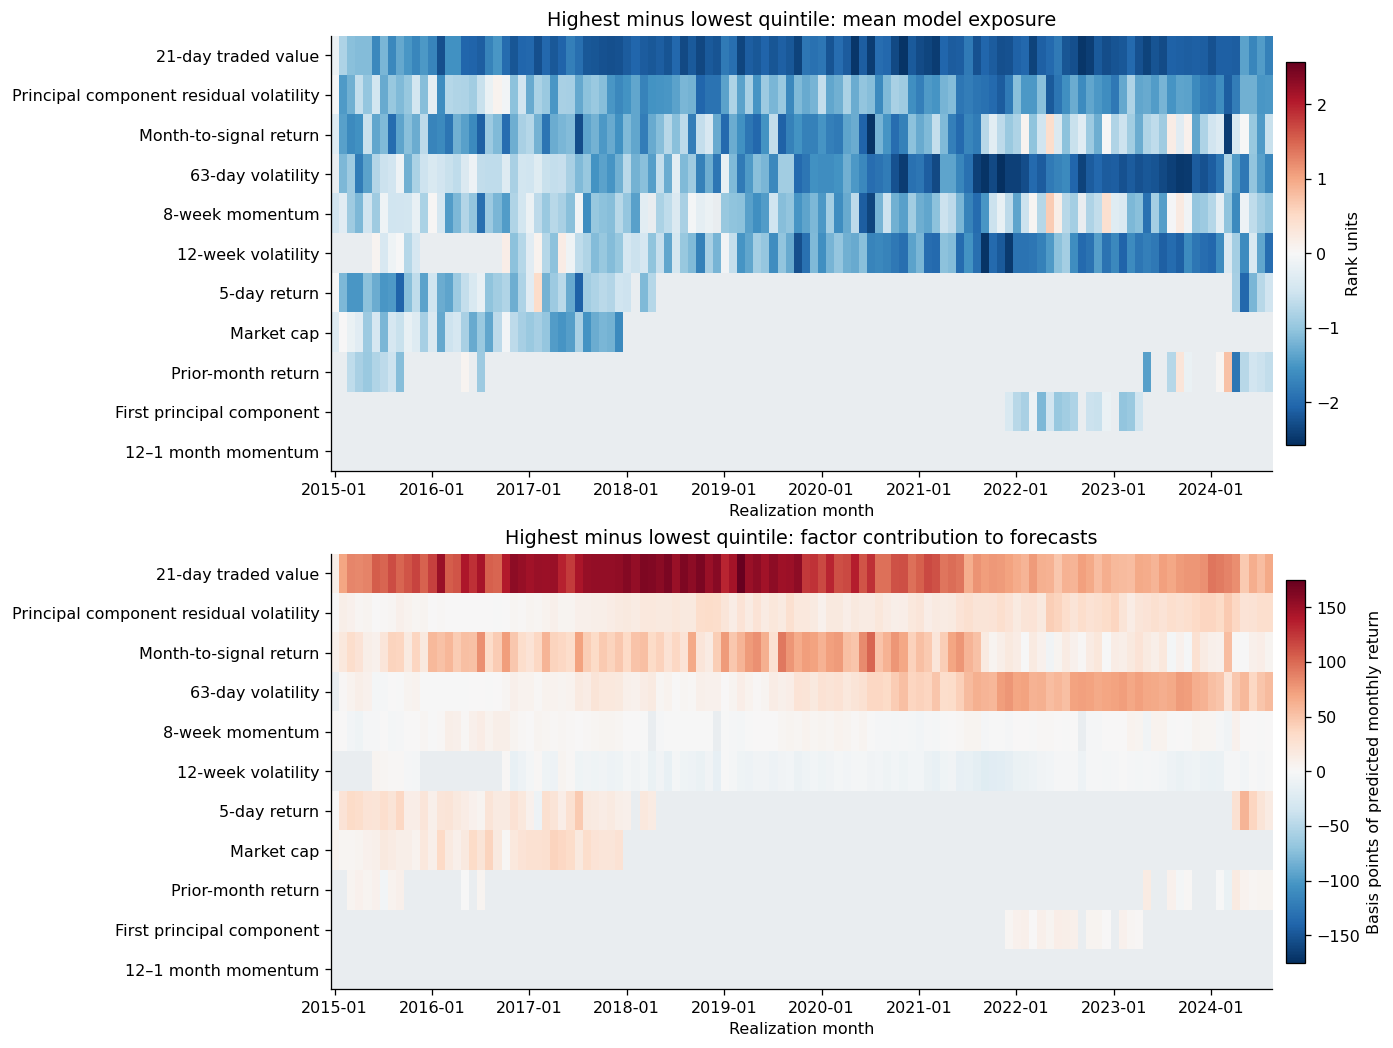

In [6]:
def plot_factor_heatmap(ax, frame, title, unit):
    order = selection_counts.index
    matrix = frame.reindex(columns=order).T
    values = matrix.to_numpy()
    limit = max(1e-8, np.nanmax(np.abs(values)))
    palette = plt.get_cmap("RdBu_r").copy()
    palette.set_bad("#e9edf0")
    chart = ax.imshow(np.ma.masked_invalid(values), aspect="auto", interpolation="nearest",
                      cmap=palette, norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    ax.set(yticks=np.arange(len(order)), yticklabels=[FACTOR_LABELS[name] for name in order],
           title=title)
    ax.grid(False)
    ax.figure.colorbar(chart, ax=ax, label=unit, shrink=0.88, pad=0.015)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), layout="constrained")
plot_factor_heatmap(ax1, exposure_spread, "Highest minus lowest quintile: mean model exposure", "Rank units")
plot_factor_heatmap(ax2, contribution_spread * 1e4, "Highest minus lowest quintile: factor contribution to forecasts",
                    "Basis points of predicted monthly return")
ticks = np.arange(0, len(realised), 12)
labels = realised.index[ticks].strftime("%Y-%m")
for ax in (ax1, ax2):
    ax.set(xticks=ticks, xticklabels=labels, xlabel="Realization month")
plt.show()

热图按**实现月**显示，所有暴露和系数取自上一月的信号日。灰色表示该因子当月未入选，或该组没有可汇总的信号。

下一格可以切换查看月份、股票组以及展示的是排名暴露还是预测贡献。设置 `DETAIL_GROUP = None` 可显示完整 50 只。另把两个压力窗口内的组间预测差按因子汇总为基点，方便定位具体月份和股票。

In [7]:
DETAIL_MONTH = "2015-07"  # 实现月。用于选组的信号产生于上月。
DETAIL_GROUP = "Q1"       # 也可以设为 Q2 到 Q5，或 None 查看全部 50 只。
DETAIL_VALUE = "model_exposure"  # 或 rank_exposure、raw_feature、forecast_contribution。

detail_date = pd.Period(DETAIL_MONTH, freq="M").end_time.normalize()
detail_factors = factor_screen.loc[
    factor_screen["realization_date"].eq(detail_date) & factor_screen["selected"],
    ["factor", "months", "mean_rank_ic", "p_value", "q_value", "coefficient"],
].sort_values("q_value").set_index("factor")
if detail_factors.empty:
    raise ValueError(f"{DETAIL_MONTH} 无入选因子，或超出样本外月份。")
display(detail_factors.style.format("{:.4f}", subset=detail_factors.columns.difference(["months"])))

detail = stock_factor_exposures.loc[stock_factor_exposures["realization_date"].eq(detail_date)]
if DETAIL_GROUP is not None:
    detail = detail.loc[detail["quintile"].eq(DETAIL_GROUP)]
detail_values = detail.pivot(
    index=["score_rank", "asset", "quintile", "fresh_signal"], columns="factor", values=DETAIL_VALUE,
).sort_index().reindex(columns=detail_factors.index)
display(detail_values.style.format("{:.4f}", na_rep="—"))

window_factor_contribution = pd.DataFrame({
    window: (contribution_spread.loc[start:end].fillna(0.0).mean() * 1e4)
    for window, (start, end) in STRESS_WINDOWS.items()
}).reindex(selection_counts.index)
window_factor_contribution["Selected months (full sample)"] = selection_counts
display(window_factor_contribution.style.format(
    "{:+.2f}", subset=list(STRESS_WINDOWS), na_rep="—",
))

,months,mean_rank_ic,p_value,q_value,coefficient
factor,,,,,
log_size,72,-0.0773,0.0005,0.0033,-0.0013
log_amount_21d,72,-0.1239,0.0005,0.0033,-0.0071
return_5d,72,-0.0445,0.0005,0.0033,-0.0023
momentum_8w,72,-0.0620,0.0005,0.0033,0.0006
return_month_to_signal,72,-0.0622,0.0005,0.0033,-0.0020
volatility_63d,72,-0.0470,0.0010,0.0055,-0.0011
pca_residual_volatility,72,-0.0329,0.0050,0.0237,-0.0004
lagged_month_return,72,-0.0399,0.0140,0.0581,-0.0012
volatility_12w,72,-0.0318,0.0170,0.0627,0.0009


,,,factor,log_size,log_amount_21d,return_5d,momentum_8w,return_month_to_signal,volatility_63d,pca_residual_volatility,lagged_month_return,volatility_12w
score_rank,asset,quintile,fresh_signal,,,,,,,,,
1,300211.SZ,Q1,True,-1.3241,-1.6420,-1.4939,1.2097,-1.6551,0.9868,-0.2248,1.6488,1.4441
2,300176.SZ,Q1,True,-1.5848,-1.6219,-1.3908,0.8696,-1.4488,1.0472,-1.2355,1.5159,1.1161
3,000803.SZ,Q1,True,-1.4889,-1.5882,-1.5679,-0.1298,-0.7936,0.9849,0.9665,0.5047,1.4851
4,300218.SZ,Q1,True,-1.5747,-1.5781,-1.6641,0.0165,-0.6941,0.8563,0.1664,0.5502,0.5811
5,300277.SZ,Q1,True,-1.3863,-1.6824,-0.8596,-0.7316,-1.6533,1.0083,-0.8744,1.2467,0.9337
6,300097.SZ,Q1,True,-1.6404,-1.5445,-0.9834,0.0000,0.0000,0.0000,1.1169,-1.2408,0.0000
7,300354.SZ,Q1,True,-1.0010,-1.5983,-1.3839,-0.8325,-1.1719,0.8621,0.0000,0.3954,0.0994
8,002679.SZ,Q1,True,-1.3846,-1.6690,-0.4298,0.3462,-1.1085,-0.4179,0.0000,1.1222,-0.5032
9,600758.SH,Q1,True,-1.6202,-1.5192,-0.6739,0.7480,-0.3068,0.2426,-1.2231,0.8143,0.4458


,2015 年股灾（6–8 月）,2022 年下半年（7–12 月）,Selected months (full sample)
factor,,,
log_amount_21d,+107.50,+62.77,116
pca_residual_volatility,+2.17,+28.04,116
return_month_to_signal,+22.62,+9.78,116
volatility_63d,-1.48,+66.90,115
momentum_8w,-1.21,-0.58,113
volatility_12w,+3.19,-3.22,101
return_5d,+24.73,+0.00,44
log_size,+13.46,+0.00,36
lagged_month_return,+3.03,+0.00,20


### 为什么固定池等权组合波动更大、两次回撤表现不同

- **组合的波动主要来自股票同步涨跌。** 全样本中，固定池净等权的年化波动为 **33.76%**，中证 500 价格指数为 **24.46%**。把 50 只股票的月收益按等权合成，个股间协方差项占组合月收益方差约 **94.7%**。等权分散了单只股票的波动，但这个固定池里的股票经常一起涨跌。
- **2015 年股灾，固定池里的多数股票连续下跌。** 6、7、8 月分别有 **38、38、42 只**股票下跌，三个月累计有 **45 只**亏损，五个预测组也全部收跌。固定池毛等权跌 **40.45%**，净等权跌 **39.75%**，同期中证 500 跌 **33.97%**。扣费前的全池跌幅已经更深，这段超额下跌的直接来源是池内股票普遍同跌。
- **2022 年下半年，8–9 月的集中下跌压低了净值低点，10–11 月的反弹改善了期末结果。** 9 月固定池有 **45 只**股票下跌，毛等权跌 **8.94%**，中证 500 跌 **7.18%**。10、11 月固定池毛等权分别反弹 **5.33%** 和 **7.25%**，两个月涨幅均超过指数。整个下半年，固定池净等权的最大回撤略深（**−12.06% 对 −11.47%**），但累计跌幅更小（**−0.94% 对 −9.14%**）。

因子暴露解释模型在这些月份把哪些股票排得更高。2015 年股灾期间，21 日成交额因子平均拉开了约 **108 个基点**的最高组与最低组月度预测差，而五组实际收益仍同时下跌。固定池净等权主要反映这 50 只股票的共同走势。上方的因子贡献是对**预测收益**的拆解，以上组合回撤解释则来自**实际收益**。

后续可以直接用 `stock_factor_exposures`、`quintile_factor_exposures`、`factor_screen` 和 `quintile_monthly`。如需用其他工具接着分析，把下面的 `EXPORT_CSV` 改为 `True`。

In [8]:
EXPORT_CSV = True
if EXPORT_CSV:
    export_dir = root / ".cache" / "part1-analysis"
    export_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in {
        "stock_monthly": stock_panel,
        "factor_screen": factor_screen,
        "stock_factor_exposures": stock_factor_exposures,
        "quintile_factor_exposures": quintile_factor_exposures,
    }.items():
        frame.to_csv(export_dir / f"{name}.csv", index=False)
    quintile_monthly.join(monthly_benchmarks).join(spread).join(fresh_spread).to_csv(
        export_dir / "quintile_monthly_returns.csv", index_label="realization_date",
    )
    print(export_dir)

.cache/part1-analysis
